# DataForce Milestone 1: engine demo

**All data in this notebook is SYNTHETIC.** It is generated by code with a *known ground truth*: some effects
are planted on purpose (for example "inbound leads win more"), others are deliberately absent. No real
customer, company or person appears here. That lets us check the engine against the answer key.

**What "not verified" means.** Every number comes from code, with a confidence interval (the range the true
value plausibly lies in). A comparison such as "inbound wins more than the rest" is shown as a **verified**
fact only if it passes every gate: enough deals (and enough wins and losses), a narrow enough interval, and a
significance test that still holds after correcting for the many comparisons we run at once (false-discovery
control). If any gate fails the result is **not verified**: it is listed with its reasons and must not be
read as a finding. "Not verified" does not mean "false"; it means "not enough evidence". The LLM never
calculates anything.

Conventions: rates, differences and intervals are fractions in the engine and are shown here as percentage
points (pts); cycle length is in days; amounts are in EUR.

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
here = pathlib.Path.cwd().resolve()
backend = next(p / "backend" for p in [here, *here.parents] if (p / "backend" / "app").is_dir()) \
    if not (here / "app").is_dir() else here
os.chdir(backend)
sys.path.insert(0, str(backend))

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200, "display.max_colwidth", 70, "display.max_rows", 200)

from app.config import get_settings
from app.db.session import SessionLocal
from app.demo.generator import generate
from app.demo.loader import load_dataset
from app.demo.check import check_against_truth
from app.demo.inmemory import deal_rows
from app.domain.enums import StatStatus, Metric, Dimension
from app.services import analytics, workspaces
from app.stats.engine import gate_config_from_settings, scan, overall
print("setup ok (database address is not printed)")

setup ok (database address is not printed)


## 1. Generate and load the synthetic datasets (seed 42, replace = True)

In [2]:
SEED = 42
datasets, ws_ids = {}, {}
with SessionLocal() as s:
    for variant in ("planted", "noise"):
        ds = generate(variant, SEED, 350)
        counts = load_dataset(s, ds, workspace_slug=f"demo-{variant}-{SEED}", replace=True)
        datasets[variant] = ds
        ws_ids[variant] = counts["workspace_id"]
        print(variant, {k: v for k, v in counts.items() if k not in ("workspace_id",)})
    s.commit()
print()
print("Planted effects (the answer key):")
for e in datasets["planted"].ground_truth.planted:
    print(f"  {e.dimension.value}={e.group}: {e.metric.value} {e.direction} ({e.magnitude})")
print("Small groups that must stay 'not verified':", datasets["planted"].ground_truth.small_groups)
print("Dimensions with no effect at all:", [d.value for d in datasets["planted"].ground_truth.null_dimensions])

planted {'workspace_slug': 'demo-planted-42', 'users': 6, 'accounts': 122, 'contacts': 755, 'deals': 350, 'notes': 44, 'note_corrections': 4, 'comments': 20, 'comment_corrections': 2}


noise {'workspace_slug': 'demo-noise-42', 'users': 6, 'accounts': 122, 'contacts': 755, 'deals': 350, 'notes': 44, 'note_corrections': 4, 'comments': 20, 'comment_corrections': 2}

Planted effects (the answer key):
  lead_source=inbound: win_rate higher (+40 pts win rate (70% vs ~27%))
  segment=enterprise: cycle_days higher (median ~110 days vs 60 (midmarket) / 30 (smb))
  segment=smb: cycle_days lower (median ~30 days)
  segment=enterprise: deal_amount higher (median ~60k EUR vs 20k (midmarket) / 8k (smb))
  segment=smb: deal_amount lower (median ~8k EUR)
Small groups that must stay 'not verified': [(<Dimension.LEAD_SOURCE: 'lead_source'>, 'referral')]
Dimensions with no effect at all: ['industry', 'region', 'owner']


## 2. Pipeline summary (exact SQL aggregates: facts, no interval needed)

In [3]:
with SessionLocal() as s:
    summ = analytics.pipeline_summary(s, ws_ids["planted"])
df = pd.DataFrame(summ["by_stage"]).T[["count", "amount_eur"]]
df["amount_eur"] = df["amount_eur"].map("{:,.0f}".format)
display(df)
print({k: summ[k] for k in ("n_deals", "n_open", "n_closed", "n_won", "n_lost")}, f"total EUR {summ['total_amount_eur']:,.0f}")

,count,amount_eur
prospecting,8.0,"163,688"
qualification,25.0,"602,519"
proposal,30.0,"856,552"
negotiation,24.0,"759,539"
closed_won,109.0,"3,416,087"
closed_lost,154.0,"4,334,887"


{'n_deals': 350, 'n_open': 87, 'n_closed': 263, 'n_won': 109, 'n_lost': 154} total EUR 10,133,272


## 3. Overall statistics with confidence intervals

In [4]:
cfg = gate_config_from_settings(get_settings())
with SessionLocal() as s:
    rows = analytics.load_deal_rows(s, ws_ids["planted"])
ov = overall(rows, cfg)
def fmt(metric, x):
    if x is None: return "-"
    return f"{x*100:.1f}%" if metric == Metric.WIN_RATE else f"{x:,.0f}"
tbl = pd.DataFrame([{
    "metric": m.value, "value": fmt(m, v.value),
    "95% CI": f"[{fmt(m, v.ci_low)}, {fmt(m, v.ci_high)}]", "n": v.n,
    "method": v.method, "status": v.status.value, "reasons": "; ".join(v.reasons)} for m, v in ov.items()])
display(tbl)

,metric,value,95% CI,n,method,status,reasons
0,win_rate,41.4%,"[35.7%, 47.5%]",263,wilson,verified,
1,cycle_days,52,"[47, 56]",252,bootstrap-percentile median,verified,
2,deal_amount,"18,694","[16,444, 21,047]",325,bootstrap-percentile median,verified,


## 4. Scan: verified versus not-verified findings
Every dimension x group x metric is compared with "the rest" (all other deals). Benjamini-Hochberg false-discovery
control is applied over the whole scan. Sorted: verified first.

In [5]:
with SessionLocal() as s:
    report = analytics.run_scan(s, ws_ids["planted"])
    s.commit()
def diff_txt(f):
    if f.diff is None: return "-"
    if f.diff_ci_low is None or f.diff_ci_high is None: return f"{f.diff:+.3g} (no CI)"
    if f.metric == Metric.WIN_RATE:
        return f"{f.diff*100:+.1f} pts [{f.diff_ci_low*100:+.1f}, {f.diff_ci_high*100:+.1f}]"
    return f"{f.diff:+,.0f} [{f.diff_ci_low:+,.0f}, {f.diff_ci_high:+,.0f}]"
def scan_table(rep):
    out = pd.DataFrame([{
        "dimension": f.dimension.value, "group": f.group, "metric": f.metric.value,
        "group vs rest": f"{fmt(f.metric, f.group_value)} vs {fmt(f.metric, f.rest_value)}",
        "diff [95% CI]": diff_txt(f), "q": None if f.q_value is None else round(f.q_value, 4),
        "n": f"{f.n_group}/{f.n_rest}", "status": f.status.value, "reasons": "; ".join(f.reasons),
        "_v": f.status != StatStatus.VERIFIED} for f in rep.findings])
    return out.sort_values(["_v", "q"], na_position="last").drop(columns="_v").reset_index(drop=True)
st = scan_table(report)
n_ver = (st["status"] == "verified").sum()
print(f"{n_ver} verified of {len(st)} comparisons")
print("\nVERIFIED:")
display(st[st["status"] == "verified"])
print("NOT VERIFIED (top 15 by q; reasons say why):")
display(st[st["status"] != "verified"].head(15))

9 verified of 93 comparisons

VERIFIED:


,dimension,group,metric,group vs rest,diff [95% CI],q,n,status,reasons
0,lead_source,inbound,win_rate,72.5% vs 24.2%,"+48.4 pts [+35.9, +58.6]",0.0000,91/149,verified,
1,lead_source,outbound,win_rate,10.0% vs 65.7%,"-55.7 pts [-64.3, -44.7]",0.0000,100/140,verified,
2,segment,enterprise,cycle_days,106 vs 41,"+66 [+53, +74]",0.0000,64/188,verified,
3,segment,enterprise,deal_amount,"61,607 vs 13,240","+48,366 [+41,342, +64,165]",0.0000,85/240,verified,
4,segment,smb,cycle_days,31 vs 74,"-43 [-52, -35]",0.0000,107/145,verified,
5,segment,smb,deal_amount,"8,231 vs 33,256","-25,025 [-30,128, -19,453]",0.0000,130/195,verified,
6,amount_band,50k+,cycle_days,96 vs 44,"+52 [+42, +68]",0.0000,48/186,verified,
7,amount_band,<10k,cycle_days,30 vs 63,"-33 [-41, -26]",0.0000,61/173,verified,
8,segment,midmarket,cycle_days,60 vs 41,"+19 [+6, +25]",0.0341,81/171,verified,


NOT VERIFIED (top 15 by q; reasons say why):


,dimension,group,metric,group vs rest,diff [95% CI],q,n,status,reasons
9,lead_source,referral,win_rate,72.0% vs 39.1%,"+32.9 pts [+12.3, +48.0]",0.0239,25/215,not_verified,group: n = 25 < 30; group: only 7 losses (< 10)
10,industry,healthcare,win_rate,60.0% vs 38.5%,"+21.5 pts [+3.9, +37.2]",0.2160,35/221,not_verified,group: CI ±15.4 pts > ±15 pts; q = 0.216 >= 0.05
11,industry,energy,win_rate,24.2% vs 43.9%,"-19.7 pts [-32.9, -1.8]",0.2888,33/223,not_verified,group: only 8 wins (< 10); q = 0.289 >= 0.05
12,amount_band,10-50k,win_rate,48.9% vs 36.0%,"+12.9 pts [+0.5, +24.7]",0.3731,131/114,not_verified,q = 0.373 >= 0.05
13,owner,Philippa Montbelair,cycle_days,47 vs 53,"-6 [-22, +6]",0.5720,45/207,not_verified,"q = 0.572 >= 0.05; difference CI [-22, 6] includes 0"
14,segment,midmarket,deal_amount,"20,771 vs 15,879","+4,892 [-190, +9,921]",0.5795,110/215,not_verified,"q = 0.58 >= 0.05; difference CI [-190, 9.92e+03] includes 0"
15,owner,Anselme Thistlegrove,cycle_days,66 vs 50,"+16 [+0, +29]",0.6153,38/214,not_verified,q = 0.615 >= 0.05
16,region,Occitanie,win_rate,28.6% vs 42.7%,"-14.1 pts [-28.1, +3.6]",0.7580,35/211,not_verified,"q = 0.758 >= 0.05; difference CI [-28.1, +3.6] pts includes 0"
17,lead_source,outbound,deal_amount,"17,631 vs 20,620","-2,990 [-9,357, +1,596]",0.7620,120/178,not_verified,"q = 0.762 >= 0.05; difference CI [-9.36e+03, 1.6e+03] includes 0"
18,owner,Lachlan Dunsmoor,deal_amount,"15,008 vs 19,363","-4,356 [-9,839, +1,002]",0.7620,53/272,not_verified,group: CI ±30% of the median > ±30%; q = 0.762 >= 0.05; difference...


## 5. Plots: win rate by lead source (Wilson CI) and cycle length by segment (median, bootstrap CI)

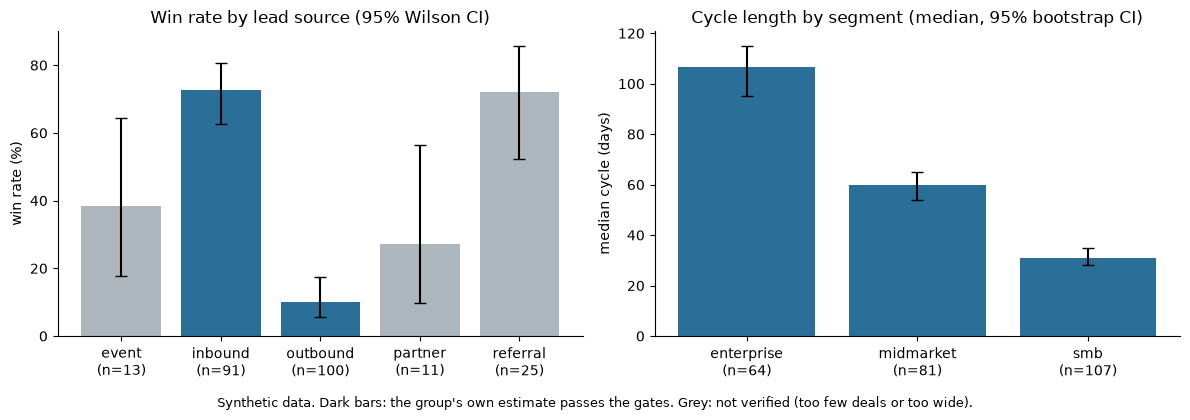

In [6]:
def group_plot(ax, rep, dim, metric, scale, ylabel):
    gs = [g for g in rep.groups if g.dimension == dim and metric in g.stats]
    vals = [g.stats[metric] for g in gs]
    x = range(len(gs))
    y = [v.value * scale for v in vals]
    lo = [y_ - v.ci_low * scale for y_, v in zip(y, vals)]
    hi = [v.ci_high * scale - y_ for y_, v in zip(y, vals)]
    cols = ["#2a6f97" if v.status == StatStatus.VERIFIED else "#adb5bd" for v in vals]
    ax.bar(x, y, color=cols, yerr=[lo, hi], capsize=4)
    ax.set_xticks(list(x)); ax.set_xticklabels([f"{g.group}\n(n={v.n})" for g, v in zip(gs, vals)])
    ax.set_ylabel(ylabel); ax.spines[["top", "right"]].set_visible(False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
group_plot(axes[0], report, Dimension.LEAD_SOURCE, Metric.WIN_RATE, 100, "win rate (%)")
axes[0].set_title("Win rate by lead source (95% Wilson CI)")
group_plot(axes[1], report, Dimension.SEGMENT, Metric.CYCLE_DAYS, 1, "median cycle (days)")
axes[1].set_title("Cycle length by segment (median, 95% bootstrap CI)")
fig.text(0.5, -0.03, "Synthetic data. Dark bars: the group's own estimate passes the gates. Grey: not verified (too few deals or too wide).", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## 6. Ground-truth check (planted dataset)

In [7]:
res = check_against_truth(report, datasets["planted"].ground_truth)
print(res.summary())
print("\nFound (planted effect and a matching verified finding):")
for e in res.found: print("  OK  ", e.dimension.value, e.group, e.metric.value, e.direction, "|", e.magnitude)
print("Missed:", [(e.dimension.value, e.group) for e in res.missed])
sm = datasets["planted"].ground_truth.small_groups
print("\nSmall groups", sm, "-> none verified:", res.small_groups_ok)
nulls = {d.value for d in datasets["planted"].ground_truth.null_dimensions}
print("Verified findings on null dimensions (false positives):", len(res.false_positives), "| null dims:", sorted(nulls))
assert res.passed

passed=True found=5 missed=0 small_groups_ok=True false_positives=0 other_real=4

Found (planted effect and a matching verified finding):
  OK   lead_source inbound win_rate higher | +40 pts win rate (70% vs ~27%)
  OK   segment enterprise cycle_days higher | median ~110 days vs 60 (midmarket) / 30 (smb)
  OK   segment smb cycle_days lower | median ~30 days
  OK   segment enterprise deal_amount higher | median ~60k EUR vs 20k (midmarket) / 8k (smb)
  OK   segment smb deal_amount lower | median ~8k EUR
Missed: []

Small groups [(<Dimension.LEAD_SOURCE: 'lead_source'>, 'referral')] -> none verified: True
Verified findings on null dimensions (false positives): 0 | null dims: ['industry', 'owner', 'region']


## 7. Noise variant: nothing should be verified, but a chance finding can appear
On pure noise the engine usually says "not verified" everywhere. Benjamini-Hochberg bounds the *share* of false findings among the reported ones, not the chance of at least one: over 100 seeds at 350 deals about 4% of noise datasets show one. Seed 42 is such a case, kept on purpose as an honest example. The engine is not never wrong.

In [8]:
with SessionLocal() as s:
    noise_report = analytics.run_scan(s, ws_ids["noise"])
    s.commit()
nres = check_against_truth(noise_report, datasets["noise"].ground_truth)
n_noise_verified = sum(f.status == StatStatus.VERIFIED for f in noise_report.findings)
print(f"Noise: {n_noise_verified} verified out of {len(noise_report.findings)} comparisons.", nres.summary())
display(scan_table(noise_report).head(8))
# At most a handful of chance findings (seed 42 shows one); never a pile of them.
assert n_noise_verified <= 2

Noise: 1 verified out of 93 comparisons. passed=False found=0 missed=0 small_groups_ok=True false_positives=1 other_real=0


,dimension,group,metric,group vs rest,diff [95% CI],q,n,status,reasons
0,owner,Anselme Penhallow,cycle_days,86 vs 60,"+26 [+17, +42]",0.0279,43/217,verified,
1,segment,smb,cycle_days,71 vs 59,"+12 [-1, +25]",0.3158,107/153,not_verified,"q = 0.316 >= 0.05; difference CI [-1, 25] includes 0"
2,industry,healthcare,win_rate,51.4% vs 29.9%,"+21.6 pts [+4.5, +38.1]",0.3158,35/221,not_verified,group: CI ±15.7 pts > ±15 pts; q = 0.316 >= 0.05
3,region,Grand Est,cycle_days,84 vs 61,"+22 [+2, +52]",0.3158,38/205,not_verified,q = 0.316 >= 0.05
4,region,Provence-Alpes-Côte d'Azur,deal_amount,"13,403 vs 20,716","-7,312 [-13,216, -1,426]",0.3158,45/259,not_verified,group: CI ±34% of the median > ±30%; q = 0.316 >= 0.05
5,amount_band,<10k,win_rate,45.0% vs 27.4%,"+17.6 pts [+3.9, +31.4]",0.3158,60/186,not_verified,q = 0.316 >= 0.05
6,segment,midmarket,win_rate,41.9% vs 27.7%,"+14.2 pts [+2.1, +26.4]",0.3247,86/177,not_verified,q = 0.325 >= 0.05
7,owner,Philippa Montbelair,cycle_days,51 vs 69,"-18 [-28, -2]",0.3247,46/214,not_verified,q = 0.325 >= 0.05


## 8. Robustness: 20 seeds of each variant (in memory, no database)
For each seed we generate a fresh synthetic dataset, scan it, and check against its own truth.
Planted: pass rate and false positives. Noise: how many seeds show *any* verified finding (the false-alarm rate).

In [9]:
import time
t0 = time.time()
rows_out = []
for variant in ("planted", "noise"):
    passed = fp = any_ver = missed = 0
    for seed in range(1, 21):
        ds = generate(variant, seed, 350)
        rep = scan(deal_rows(ds), cfg)
        r = check_against_truth(rep, ds.ground_truth)
        passed += r.passed; fp += len(r.false_positives); missed += len(r.missed)
        any_ver += any(f.status == StatStatus.VERIFIED for f in rep.findings)
    rows_out.append({"variant": variant, "seeds": 20, "passed": passed, "pass rate": f"{passed/20:.0%}",
                     "planted effects missed": missed, "false-positive findings": fp,
                     "seeds with any verified finding": any_ver})
display(pd.DataFrame(rows_out))
print(f"elapsed {time.time()-t0:.0f}s")

,variant,seeds,passed,pass rate,planted effects missed,false-positive findings,seeds with any verified finding
0,planted,20,19,95%,0,1,20
1,noise,20,19,95%,0,1,1


elapsed 41s
